# Reducing Bias With Kernelization

## About This Project

In this project, you will reduce bias by implementing a kernelized support vector machine (SVM). You will generate linearly separable and non-linearly separable datasets, write kernel, loss, and gradient functions for SVMs that support a variety of different kernels, and then visualize the decision boundary that is created.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

### Python Initialization

Please run the following code to initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
import numpy as np

# Interactive matplotlib plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


### Generate and Visualize Data

Before we start, let's generate some data and visualize the training set. We are going to use the linearly separable data that we used in our previous project!

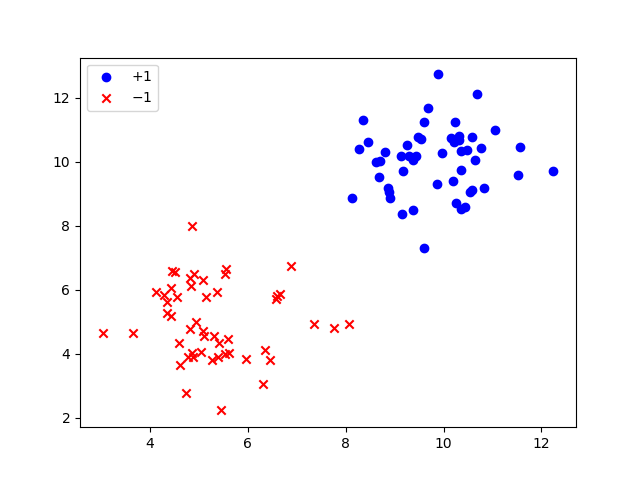

In [2]:
xTr, yTr = generate_data()
visualize_2D(xTr, yTr)

## Kernel SVM

In this assignment, you need to implement three functions:

1. `computeK` to compute the kernel function efficiently

2. `loss` to calculate the kernelized version of the unconstrained squared hinge loss and the regularizer

3. `grad` to calculate the gradients of the loss with respect to the model parameters of the kernel SVM

### Part One: Compute Kernel Matrices [Graded]

You will implement a function **`computeK`** that calculates the values of different kernel functions given inputs `X` and `Z`.

The function `computeK` will return a matrix $\mathsf{K}$ with entries of the form

$$
\mathsf{K}_{ij} = \mathsf{K}(\mathbf{x}_i,\mathbf{z}_j) = \phi(\mathbf{x}_i)^\top \phi(\mathbf{z}_j)
$$

As you have seen so far, computing $\phi(\mathbf{x}_i)$ and $\phi(\mathbf{z}_j)$ explicitly and taking the dot product can be computationally expensive. Consequently, we will use the dot product expression $\mathsf{K}(\mathbf{x}_i, \mathbf{z}_j)$ without ever computing $\phi(\mathbf{x}_i)$ and $\phi(\mathbf{z}_j)$.

`computeK` takes in the parameter `kerneltype` to decide which of the three different kernel functions to calculate:

- `kerneltype="linear"` corresponds to $\mathsf{K}(\mathbf{X},\mathbf{Z}) = \mathbf{X}^\top \mathbf{Z}$

- `kerneltype="polynomial"` corresponds to $\mathsf{K}(\mathbf{X},\mathbf{Z}) = \left(1 + \mathbf{X}^\top\mathbf{Z} \right)^{p}$, where the value of `kpar` is $p$

- `kerneltype="rbf"` corresponds to $\mathsf{K}(\mathbf{X},\mathbf{Z}) = \exp\left(-\dfrac{\lVert\mathbf{X}-\mathbf{Z}\rVert^2}{\sigma^2}\right)$, where the value of `kpar` is $\dfrac{1}{\sigma^2}$

**Implementation Notes:**

- When calculating the RBF kernel, you can use the `l2distance(X, Z)` function that we have provided to you. It calculates the pairwise L2-distance $\lVert\mathbf{X} - \mathbf{Z}\rVert$ efficiently.

- [`np.power(a, p)`](https://numpy.org/doc/stable/reference/generated/numpy.power.html) raises all entries of the vector or matrix `a` to the power `p`.

In [15]:
def computeK(kerneltype, X, Z, kpar=1):
    """
    Computes a matrix K such that K[i, j] = K(x_i, z_j).
    The kernel operation is defined by kerneltype with parameter kpar.

    Input:
        kerneltype: "linear", "polynomial", or "rbf'"
        X: nxd data matrix
        Z: mxd data matrix
        kpar: Kernel parameter (inverse sigma^2 for "rbf", degree p for "polynomial")

    Output:
        K: nxm kernel matrix
    """
    assert kerneltype in ["linear", "polynomial", "rbf"], (
        "Kernel type %s not known." % kerneltype
    )
    assert X.shape[1] == Z.shape[1], "Input dimensions do not match"

    K = None

    # YOUR CODE HERE
    if kerneltype == "linear":
        K = np.dot(X,Z.T)
    elif kerneltype == "polynomial":
        K = (np.dot(X,Z.T) + 1) ** kpar
    elif kerneltype == "rbf":
        sq_distance = np.sum((X[:, None, :] - Z[None, :, :])**2, axis=2)
        K = np.exp(-sq_distance/kpar)
    # END OF YOUR CODE

    return K

Run the next cell to check your implementation of `computeK`.

In [16]:
# Generate data for testing kernel matrices
xTr_test, yTr_test = generate_data(100)
xTr_test2, yTr_test2 = generate_data(50)
n, d = xTr_test.shape


def computeK_test1():
    """
    Checks that kernel matrices have the correct shape
    """
    s1 = computeK("rbf", xTr_test, xTr_test2, kpar=1).shape == (100, 50)
    s2 = computeK("polynomial", xTr_test, xTr_test2, kpar=1).shape == (100, 50)
    s3 = computeK("linear", xTr_test, xTr_test2, kpar=1).shape == (100, 50)
    return s1 and s2 and s3


def computeK_test2():
    """
    Checks that kernel matrices are symmetric
    """
    k_rbf = computeK("rbf", xTr_test, xTr_test, kpar=1)
    s1 = np.allclose(k_rbf, k_rbf.T)

    k_poly = computeK("polynomial", xTr_test, xTr_test, kpar=1)
    s2 = np.allclose(k_poly, k_poly.T)

    k_linear = computeK("linear", xTr_test, xTr_test, kpar=1)
    s3 = np.allclose(k_linear, k_linear.T)

    return s1 and s2 and s3


def computeK_test3():
    """
    Checks that kernel matrices are positive semi-definite
    """
    k_rbf = computeK("rbf", xTr_test2, xTr_test2, kpar=1)
    eigen_rbf = np.linalg.eigvals(k_rbf)
    eigen_rbf[np.isclose(eigen_rbf, 0)] = 0
    s1 = np.all(eigen_rbf >= 0)

    k_poly = computeK("polynomial", xTr_test2, xTr_test2, kpar=1)
    eigen_poly = np.linalg.eigvals(k_poly)
    eigen_poly[np.isclose(eigen_poly, 0)] = 0
    s2 = np.all(eigen_poly >= 0)

    k_linear = computeK("linear", xTr_test2, xTr_test2, kpar=1)
    eigen_linear = np.linalg.eigvals(k_linear)
    eigen_linear[np.isclose(eigen_linear, 0)] = 0
    s3 = np.all(eigen_linear >= 0)

    return s1 and s2 and s3


def computeK_test4():
    """
    Checks that rbf kernel matrix is correct
    """
    k = computeK("rbf", xTr_test, xTr_test2, kpar=1)
    k2 = computeK_grader("rbf", xTr_test, xTr_test2, kpar=1)
    return np.linalg.norm(k - k2) < 1e-5


def computeK_test5():
    """
    Checks that polynomial kernel matrix is correct
    """
    k = computeK("polynomial", xTr_test, xTr_test2, kpar=1)
    k2 = computeK_grader("polynomial", xTr_test, xTr_test2, kpar=1)
    return np.linalg.norm(k - k2) < 1e-5


def computeK_test6():
    """
    Checks that linear kernel matrix is correct
    """
    k = computeK("linear", xTr_test, xTr_test2, kpar=1)
    k2 = computeK_grader("linear", xTr_test, xTr_test2, kpar=1)
    return np.linalg.norm(k - k2) < 1e-5


runtest(computeK_test1, "computeK_test1")
runtest(computeK_test2, "computeK_test2")
runtest(computeK_test3, "computeK_test3")
runtest(computeK_test4, "computeK_test4")
runtest(computeK_test5, "computeK_test5")
runtest(computeK_test6, "computeK_test6")

Running Test: computeK_test1 ... ✔ Passed!
Running Test: computeK_test2 ... ✔ Passed!
Running Test: computeK_test3 ... ✔ Passed!
Running Test: computeK_test4 ... ✔ Passed!
Running Test: computeK_test5 ... ✔ Passed!
Running Test: computeK_test6 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (computeK_test1)

In [ ]:
# Auto-graded test cell worth one point (computeK_test2)

In [ ]:
# Auto-graded test cell worth one point (computeK_test3)

In [ ]:
# Auto-graded test cell worth one point (computeK_test4)

In [ ]:
# Auto-graded test cell worth one point (computeK_test5)

In [ ]:
# Auto-graded test cell worth one point (computeK_test6)

Previously in linear SVM, we could pass in $\mathbf{w}$ to calculate the unconstrained square hinge loss and the L2-regularizer. However, for the kernelized version of the loss function, $\mathbf{w}$ is written as a linear combination of the $n$ training examples $\phi(\mathbf{x}_1),\dots,\phi(\mathbf{x}_n)$ and thus we will need to pass in the coefficients in the linear combination and training points.

As we will see in the following section, after substituting $\mathbf{w}$ with a linear combination of training examples, we can simplify the kernel SVM loss function quite a bit.

### Kernelized SVM Loss Function

We assume a training set of $n$ examples. Recall how $\mathbf{w}$ could be written as a linear combination of the training samples:

$$
\mathbf{w} = \sum_{j=1}^n \alpha_j y_j\phi(\mathbf{x}_j) = \sum_{j=1}^n \beta_j\phi(\mathbf{x}_j)
$$

where we define new model parameters $\beta_j = \alpha_j y_j$ for simpler expressions going forward.

Also recall the expression for the regularizer and the unconstrained squared hinge loss over any $m$ points $\phi(\mathbf{z}_1),\dots,\phi(\mathbf{z}_m)$. If we substitute $\mathbf{w}$ into the loss, we get the following expression. **Observe that only the squared hinge loss is dependent on the $m$ points; the regularizer is independent.**

$$
\begin{aligned}
\mathcal{L}(\mathbf{w}, b) 
&= \underbrace{\mathbf{w}^\top \mathbf{w}}_{\text{L2-regularizer} } 
+ C\sum_{i=1}^{m} \underbrace{\max\left[1-y_i\left(\mathbf{w}^\top\phi(\mathbf{z}_i)+b\right),0\right]^2}_{ \text{squared hinge loss}} \\
&= \left(\sum_{j=1}^n \beta_j \phi(\mathbf{x}_j)\right)^\top \left(\sum_{j=1}^n\beta_j \phi(\mathbf{x}_j)\right)
+ C \sum_{i=1}^m \max\left[1-y_i\left(\left(\sum_{j=1}^n\beta_j\phi(\mathbf{x}_j)\right)^\top \phi(\mathbf{z}_i) + b \right), 0 \right]^{\;2} \\
&= \sum_{j=1}^n \sum_{k = 1}^n \beta_j\beta_k \phi(\mathbf{x}_j)^\top \phi(\mathbf{x}_k)
+ C \sum_{i=1}^{m} \max\left[1-y_i\left(\sum_{j=1}^n \beta_j \phi(\mathbf{x}_j)^\top \phi(\mathbf{z}_i) + b \right),0\right]^2
\end{aligned}
$$

Let us now replace all the dot product terms $\phi(\mathbf{a})^\top \phi(\mathbf{b})$ with $\mathsf{K}(\mathbf{a}, \mathbf{b})$ for all data points $\mathbf{a}, \mathbf{b}$.

$$
\mathcal{L}(\beta_1, \dots, \beta_n, b) 
= \underbrace{\sum_{j=1}^n\sum_{k=1}^n\beta_j\beta_k \mathsf{K}(\mathbf{x}_j,\mathbf{x}_k)}_{\text{L2-regularizer}}
+ C \sum_{i=1}^{m} \underbrace{\max\left[1-y_i\left(\sum_{j=1}^n \beta_j \mathsf{K} \left(\mathbf{x}_j, \mathbf{z}_i \right)+b \right), 0 \right]^2}_{\text{squared hinge loss}}
$$

Let us pause here to observe a few facts:

- When $\mathbf{w}$ is written as a linear combination of the $n$ training points, the loss is then optimized over the parameters $\beta_1, \dots, \beta_n, b$.

- The L2-regularizer is the inner product of $\mathbf{w}$ with itself. Since $\mathbf{w}$ is a linear combination of the $n$ training points, the regularizer only depends on the inner products between $n$ training points.

- The loss never needs $\phi(\mathbf{x})$ explicitly. It only needs the dot products between data points.

Now, let us move ahead and simplify the loss function to a vector form. First, we will simplify the L2-regularizer. Define the vector 

$$
\boldsymbol{\beta}= 
\begin{bmatrix}
\beta_1 \\ 
\vdots \\ 
\beta_n 
\end{bmatrix}
$$ 

Define an $n\times n$ matrix $\mathsf{K}_{nn}$ to be the kernel matrix calculated on the training set of $n$ points. Precisely, the $(j,k)$-th entry is defined to be $\mathsf{K}_{nn}[j,k] = \mathsf{K}(\mathbf{x}_j,\mathbf{x}_k)$ for all $j,k\in\{1,\dots,n\}$. Thus, the L2-regularizer can be written as the quadratic form:

$$
\sum_{j=1}^n \sum_{k=1}^n \beta_j\beta_k \mathsf{K}(\mathbf{x}_j,\mathbf{x}_k) 
= \boldsymbol{\beta}^\top \mathsf{K}_{nn} \boldsymbol{\beta}
$$

Similarly, we can define an $n\times m$ kernel matrix $\mathsf{K}_{nm}$ by setting the $(j,i)$-th entry to be $\mathsf{K}_{nm}[j,i] = \mathsf{K}(\mathbf{x}_j,\mathbf{z}_i)$ for all $j\in\{1,\dots,n\}$ and $i\in\{1,\dots,m\}$. Hence, the summation term in the hinge loss can be expressed as:

$$
\sum_{j=1}^n \beta_j\mathsf{K}(\mathbf{x}_j,\mathbf{z}_i) 
= \boldsymbol{\beta}^\top \mathsf{K}_{nm}[:, i]
$$

Here, $\mathsf{K}_{nm}[:, i]$ represents the $i$-th column of $\mathsf{K}_{nm}$.

Combining the two simplifications above, we arrive at the following final expression for the loss function:

$$
\mathcal{L}(\boldsymbol{\beta}, b) 
= \underbrace{\boldsymbol{\beta}^\top \mathsf{K}_{nn} \boldsymbol{\beta}}_{\text{L2-regularizer}}
+ C \sum_{i=1}^m \underbrace{\max\left[1-y_i\left(\boldsymbol{\beta}^\top\mathsf{K}_{nm}[:, i] + b\right), 0 \right]^2}_{\text{squared hinge loss}}
$$

**During training, we minimize the training loss, with $\mathsf{K}_{nm}$ replaced by $\mathsf{K}_{nn}$, to get the optimal $\boldsymbol{\beta}$ and $b$. Then we fix $\boldsymbol{\beta}$ and $b$ to evaluate the loss value on testing points with $\mathsf{K}_{nm}$ in the squared hinge loss.**

Note that the loss function we have above is very similar to the vanilla linear SVM. The key differences are:

1. Instead of $\mathbf{w}$, we are optimizing for $\boldsymbol{\beta}$.

2. The L2-regularizer $\mathbf{w}^\top \mathbf{w}$ is replaced by $\boldsymbol{\beta}^\top \mathsf{K}_{nn} \boldsymbol{\beta}$ to account for using $\boldsymbol{\beta}$ instead of $\mathbf{w}$.

3. The inner product $\mathbf{w}^\top \phi(\mathbf{z}_i)$ in the hinge loss is changed to $\boldsymbol{\beta}^\top \mathsf{K}_{nm}[:, i]$.

Since each entry of $\mathsf{K}_{nn}$ and $\mathsf{K}_{nm}$ can be calculated by a simple formula in `computeK`, the kernel SVM is efficiently optimizable even if the $\phi$ function is in a high-dimensional space.

### Part Two: Compute Loss [Graded]

Now you will implement the function **`loss`**. The function takes in model parameters `beta, b`, $n$ training points as `xTr, yTr`, and $m$ testing points as `xTe, yTe`, along with hyperparameters `C`, `kerneltype`, and `kpar`. You will need to calculate both kernel matrices $\mathsf{K}_{nn}$ and $\mathsf{K}_{nm}$ using `computeK` on `xTr, xTr` and `xTr, xTe`, respectively.

When we use the `loss` function later on, we are going to be a little clever by using it both for training loss and testing loss.

- During training, `loss(beta, b, xTr, yTr, xTr, yTr, C, kerneltype, kpar)` calculates the loss on $\mathsf{K}_{nn}$

- During testing, `loss(beta, b, xTr, yTr, xTe, yTe, C, kerneltype, kpar)` calculates the loss on $\mathsf{K}_{nm}$

Therefore, you should implement `loss` keeping in mind how we will call it during training and testing.

In [19]:
def loss(beta, b, xTr, yTr, xTe, yTe, C, kerneltype, kpar=1):
    """
    Calculates the loss (regularizer + squared hinge loss) for
    testing data against training data and parameters beta, b.

    Input:
        beta: n-dimensional vector that stores the linear combination coefficients
        b: Bias term (a scalar)
        xTr: nxd dimensional data matrix (training set, each row is an input vector)
        yTr: n-dimensional vector (training labels, each entry is a label)
        xTe: mxd dimensional matrix (test set, each row is an input vector)
        yTe: m-dimensional vector (test labels, each entry is a label)
        C: Scalar (constant that controls the tradeoff between L2-regularizer and hinge loss)
        kerneltype: Can be "linear", "polynomial", or "rbf"
        kpar: Kernel parameter (inverse sigma^2 for "rbf", degree p for "polynomial")

    Output:
        loss_val: Total loss (a scalar) obtained with (beta, xTr, yTr, b) on xTe and yTe
    """
    loss_val = 0.0

    # Compute the kernel values between xTr and xTr
    kernel_train = computeK(kerneltype, xTr, xTr, kpar)

    # Compute the kernel values between xTr and xTe
    kernel_test = computeK(kerneltype, xTr, xTe, kpar)

    # YOUR CODE HERE
    scores = kernel_test.T @ beta + b
    margins = yTe * scores
    hinge_losses = np.maximum(0,1 - margins)**2
    loss_val = beta @ kernel_train @ beta + C * np.sum(hinge_losses)
    # END OF YOUR CODE

    return loss_val

Run the next cell to check your implementation of `loss`.

In [20]:
# Generate data for testing your function loss()
xTr_test, yTr_test = generate_data()
n, d = xTr_test.shape


def loss_test1():
    """
    Check that loss() returns a scalar
    """
    beta = np.zeros(n)
    b = np.zeros(1)
    loss_val = loss(beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 10, "rbf")
    return np.isscalar(loss_val)


def loss_test2():
    """
    Check that loss() returns a non-negative scalar
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    loss_val = loss(beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 10, "rbf")
    return loss_val >= 0


def loss_test3():
    """
    Check that the L2-regularizer is implemented correctly
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    loss_val = loss(beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 0, "rbf")
    loss_val_grader = loss_grader(
        beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 0, "rbf"
    )
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


def loss_test4():
    """
    Check that the square hinge loss is implemented correctly
    """
    beta = np.zeros(n)
    b = np.random.rand(1)
    loss_val = loss(beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 10, "rbf")
    loss_val_grader = loss_grader(
        beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 10, "rbf"
    )
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


def loss_test5():
    """
    Check that loss() is implemented correctly
    """
    beta = np.zeros(n)
    b = np.random.rand(1)
    loss_val = loss(beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 100, "rbf")
    loss_val_grader = loss_grader(
        beta, b, xTr_test, yTr_test, xTr_test, yTr_test, 100, "rbf"
    )
    return np.linalg.norm(loss_val - loss_val_grader) < 1e-5


runtest(loss_test1, "loss_test1")
runtest(loss_test2, "loss_test2")
runtest(loss_test3, "loss_test3")
runtest(loss_test4, "loss_test4")
runtest(loss_test5, "loss_test5")

Running Test: loss_test1 ... ✔ Passed!
Running Test: loss_test2 ... ✔ Passed!
Running Test: loss_test3 ... ✔ Passed!
Running Test: loss_test4 ... ✔ Passed!
Running Test: loss_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (loss_test1)

In [ ]:
# Auto-graded test cell worth one point (loss_test2)

In [ ]:
# Auto-graded test cell worth one point (loss_test3)

In [ ]:
# Auto-graded test cell worth one point (loss_test4)

In [ ]:
# Auto-graded test cell worth one point (loss_test5)

### Part Three: Compute Gradient [Graded]

Now, you will implement the function **`grad`** that computes the gradients of the loss function with respect to the parameters, similar to what you did in the Linear SVM project. `grad` outputs the gradient with respect to $\boldsymbol{\beta}$ (`beta_grad`) and $b$ (`bgrad`). Unlike `loss`, `grad` is only called during the training phase; consequently, the input parameters don't include `xTe, yTe`. Remember that the squared hinge loss is calculated with $\mathsf{K}_{nn}$ when training, and so you would just need to call `computeK` on `xTr, xTr` here.

The gradients are given by:

$$
\begin{aligned}
\frac{\partial\mathcal{L}}{\partial\boldsymbol{\beta}} 
&= 2\mathsf{K}_{nn}\boldsymbol{\beta} 
+ C \sum_{i=1}^{n} 2\max\left[1-y_{i}\left(\boldsymbol{\beta}^\top\mathsf{K}_{nn}[:,i]+b\right),0\right] \left(-y_i\mathsf{K}_{nn}[:,i]\right)\mathbf{1}_{1-y_i\left(\boldsymbol{\beta}^\top\mathsf{K}_{nn}[:,i]+b\right) > 0} \\
\frac{\partial\mathcal{L}}{\partial b} 
&=  C \sum_{i=1}^{n} 2\max\left[1-y_i \left(\boldsymbol{\beta}^\top \mathsf{K}_{nn}[:,i]+b\right),0\right] \left(-y_i \right) \mathbf{1}_{1-y_i\left(\boldsymbol{\beta}^\top\mathsf{K}_{nn}[:,i]+b\right)>0}
\end{aligned}
$$

Here, the indicator function is defined by

$$
\mathbf{1}_{1-y_i\left(\boldsymbol{\beta}^\top\mathsf{K}_{nn}[:,i]+b\right)>0} 
= \begin{cases}
1 & \text{if }1 - y_i \left(\boldsymbol{\beta}^\top\mathsf{K}_{nn}[:,i]+b\right) > 0 \\ 
0 & \text{otherwise} 
\end{cases}
$$

In [29]:
def grad(beta, b, xTr, yTr, C, kerneltype, kpar=1):
    """
    Calculates the gradients of the loss function with respect to beta and b.

    Input:
        beta: n-dimensional vector that stores the linear combination coefficients
        b: Bias term (a scalar)
        xTr: nxd dimensional data matrix (training set, each row is an input vector)
        yTr: n-dimensional vector (training labels, each entry is a label)
        C: Scalar that controls the tradeoff between L2-regularizer and hinge loss
        kerneltype: Either "linear", "polynomial", or "rbf"
        kpar: Kernel parameter (inverse of sigma^2 for "rbf", degree p for "polynomial")

    Output:
        beta_grad, bgrad
        beta_grad:  n-dimensional vector (the gradient of loss with respect to the vector beta)
        bgrad:  Scalar (the gradient of loss with respect to the bias term b)
    """
    n, d = xTr.shape

    beta_grad = np.zeros(n)
    bgrad = np.zeros(1)

    # Compute the kernel values between xTr and xTr
    kernel_train = computeK(kerneltype, xTr, xTr, kpar)

    # YOUR CODE HERE
    beta_grad += 2 * (kernel_train @ beta)
    for i in range(n):
        scores = kernel_train[i] @ beta + b
        margin = yTr[i] * scores
        hinge = np.maximum(1-margin,0)
        beta_grad -= 2*C*yTr[i] * kernel_train[i] * hinge
        bgrad -= 2 * C * yTr[i] * hinge
    bgrad = bgrad.item()
    # END OF YOUR CODE

    return beta_grad, bgrad

Run the next cell to check your implementation of `grad`.

In [30]:
# Generate data for testing your function grad()
xTr_test, yTr_test = generate_data()
n, d = xTr_test.shape


def grad_test1():
    """
    Checks that grad() returns a tuple of length 2
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    out = grad(beta, b, xTr_test, yTr_test, 10, "rbf")
    return type(out) == tuple and len(out) == 2


def grad_test2():
    """
    Checks the dimension of gradients
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    beta_grad, bgrad = grad(beta, b, xTr_test, yTr_test, 10, "rbf")
    return len(beta_grad) == n and np.isscalar(bgrad)


def grad_test3():
    """
    Checks the gradient of the L2-regularizer
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    beta_grad, bgrad = grad(beta, b, xTr_test, yTr_test, 0, "rbf")
    beta_grad_grader, bgrad_grader = grad_grader(beta, b, xTr_test, yTr_test, 0, "rbf")
    return (np.linalg.norm(beta_grad - beta_grad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


def grad_test4():
    """
    Checks the gradient of the squared hinge loss
    """
    beta = np.zeros(n)
    b = np.random.rand(1)
    beta_grad, bgrad = grad(beta, b, xTr_test, yTr_test, 1, "rbf")
    beta_grad_grader, bgrad_grader = grad_grader(beta, b, xTr_test, yTr_test, 1, "rbf")
    return (np.linalg.norm(beta_grad - beta_grad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


def grad_test5():
    """
    Checks the gradient of the loss
    """
    beta = np.random.rand(n)
    b = np.random.rand(1)
    beta_grad, bgrad = grad(beta, b, xTr_test, yTr_test, 10, "rbf")
    beta_grad_grader, bgrad_grader = grad_grader(beta, b, xTr_test, yTr_test, 10, "rbf")
    return (np.linalg.norm(beta_grad - beta_grad_grader) < 1e-5) and (
        np.linalg.norm(bgrad - bgrad_grader) < 1e-5
    )


runtest(grad_test1, "grad_test1")
runtest(grad_test2, "grad_test2")
runtest(grad_test3, "grad_test3")
runtest(grad_test4, "grad_test4")
runtest(grad_test5, "grad_test5")

Running Test: grad_test1 ... ✔ Passed!
Running Test: grad_test2 ... ✔ Passed!
Running Test: grad_test3 ... ✔ Passed!
Running Test: grad_test4 ... ✔ Passed!
Running Test: grad_test5 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (grad_test1)

In [ ]:
# Auto-graded test cell worth one point (grad_test2)

In [ ]:
# Auto-graded test cell worth one point (grad_test3)

In [ ]:
# Auto-graded test cell worth one point (grad_test4)

In [ ]:
# Auto-graded test cell worth one point (grad_test5)

## Test the Kernelized Algorithm

Using the cell below, you can call the optimization routine that we have implemented for you to see the final loss of your model. The loss will not be 0 since it includes the non-zero regularization term. To check only squared hinge loss term, we can subtract the regularization term from the final loss.

In [31]:
beta_sol, bias_sol, final_loss = minimize(
    objective=loss, grad=grad, xTr=xTr, yTr=yTr, C=1000, kerneltype="linear", kpar=1
)
print(f"The final loss of your model is {final_loss:.4f}.")

K_nn = computeK("linear", xTr, xTr, kpar=1)
reg = beta_sol @ K_nn @ beta_sol
print(f"The final squared hinge loss of your model is {final_loss - reg:.4f}.")

The final loss of your model is 0.7167.
The final squared hinge loss of your model is 0.0002.


If everything is implemented correctly, you should be able to get a training error of zero when you run the following cell.

In [32]:
svmclassify = lambda x: np.sign(computeK("linear", x, xTr, 1).dot(beta_sol) + bias_sol)
predsTr = svmclassify(xTr)
training_err = np.mean(np.sign(predsTr) != yTr)
print(f"Training Error: {100 * training_err:.2f}%")

Training Error: 0.00%


### Visualize the Decision Boundary

Also, when you visualize the classifier, you should see a max margin separator.

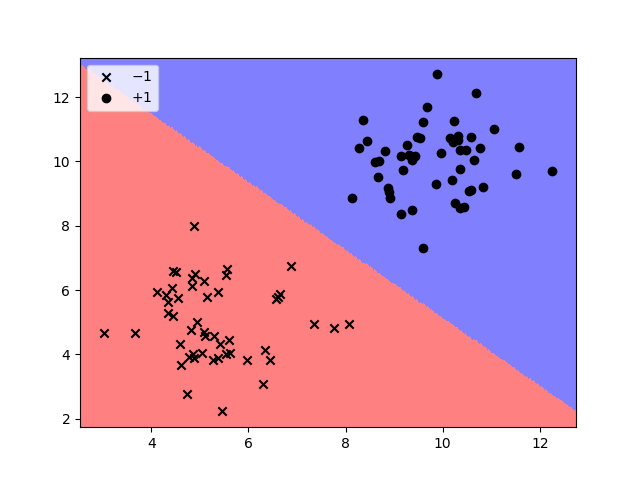

In [33]:
visclassifier(svmclassify, xTr, yTr)

Let's visualize a different kind of non-linear data, a spiral dataset.

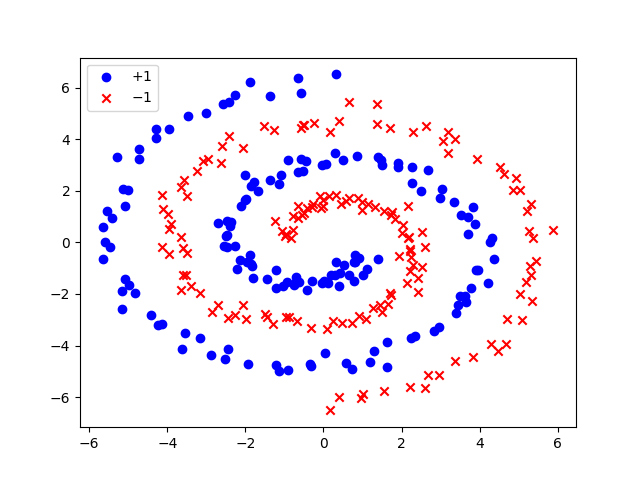

In [34]:
xTr_spiral, yTr_spiral, xTe_spiral, yTe_spiral = spiraldata()
visualize_2D(xTr_spiral, yTr_spiral)

Since the dataset is non-linear, we are going to use the RBF kernel.

In [35]:
beta_sol_spiral, bias_sol_spiral, final_loss_spiral = minimize(
    objective=loss,
    grad=grad,
    xTr=xTr_spiral,
    yTr=yTr_spiral,
    C=100,
    kerneltype="rbf",
    kpar=1,
)
print(f"The final loss of your model is {final_loss_spiral:.4f}.")

K_nn = computeK("rbf", xTr_spiral, xTr_spiral, kpar=1)
reg = beta_sol_spiral @ K_nn @ beta_sol_spiral
print(f"The final squared hinge loss of your model is {final_loss_spiral - reg:.4f}.")

The final loss of your model is 78.1411.
The final squared hinge loss of your model is 0.8950.


If you do everything correctly, your training error and test error should both be zero!

In [36]:
svmclassify_spiral = lambda x: np.sign(
    computeK("rbf", xTr_spiral, x, 1).transpose().dot(beta_sol_spiral) + bias_sol_spiral
)

predsTr_spiral = svmclassify_spiral(xTr_spiral)
training_err_spiral = np.mean(predsTr_spiral != yTr_spiral)
print(f"Training Error: {100 * training_err_spiral:.2f}%")

predsTe_spiral = svmclassify_spiral(xTe_spiral)
test_err_spiral = np.mean(predsTe_spiral != yTe_spiral)
print(f"Test Error: {100 * test_err_spiral:.2f}%")

Training Error: 0.00%
Test Error: 0.00%


Now, let's visualize the classifier on the spiral dataset!

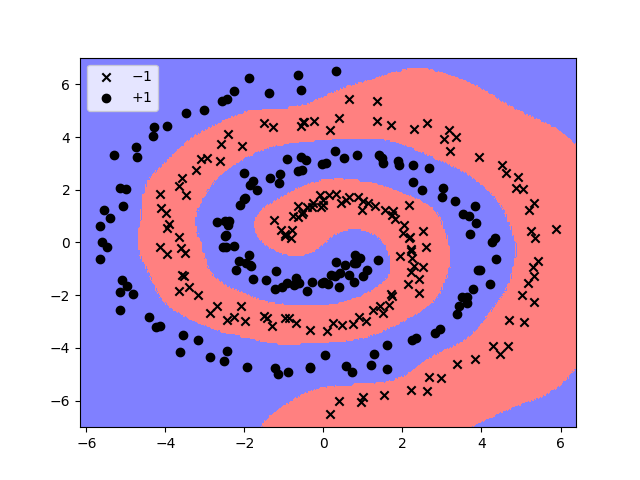

In [37]:
visclassifier(svmclassify_spiral, xTr_spiral, yTr_spiral)

### Interactive Demo

Running the code below will create an interactive window where you can click to add new data points to see how a kernel SVM with RBF kernel will respond. There may be a significant delay between clicks. You can rerun the cell to start over.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. Start the interactive demo by clicking the grid to add a positive point.
3. Click to add a positive point or shift+click to add a negative point.
4. You may notice a slight delay when adding points to the visualization.


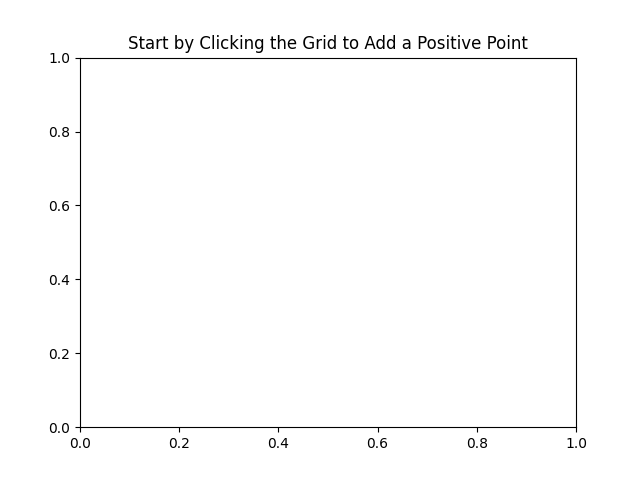

In [38]:
# Initialize empty array of width 2 to store training points
xy_data = np.empty((0, 2))

# Initialize empty array of width 1 to store training labels
label_data = np.empty((0, 1))


def onclick_classifier(event):
    """
    Visualize kernel SVM classifier by adding new points
    """
    global xy_data, label_data

    # Click to add a positive point
    if event.key is None:
        label = 1
    
    # Shift+click to add a negative point
    if event.key == "shift":
        label = -1

    # Create position vector for new point
    pos = np.array([[event.xdata, event.ydata]])

    # Add new point and label to training data
    xy_data = np.vstack((xy_data, pos))
    label_data = np.append(label_data, label)

    # Create kernel SVM function
    svmC = 10
    beta_sol, bias_sol, final_loss = minimize(
        objective=loss,
        grad=grad,
        xTr=xy_data,
        yTr=label_data,
        C=svmC,
        kerneltype="rbf",
        kpar=1,
    )
    func = lambda x: np.sign(
        computeK("rbf", xy_data, x, 1).transpose().dot(beta_sol) + bias_sol
    )

    # Return 300 evenly spaced numbers over this interval
    res = 300
    xrange = np.linspace(0, 1, res)
    yrange = np.linspace(0, 1, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Test all points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = func(xTe)

    # Reshape it back together to make our grid
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration
    plt.cla()                                  # Clear axes
    plt.xlim((0, 1))                           # x-axis limits
    plt.ylim((0, 1))                           # y-axis limits
    labels = ["$-1$", "$+1$"]                  # Labels for training points
    symbols = ["x", "o"]                       # "x" for -1 and "o" for +1 (training)
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1 (predictions)

    # Get class values from training labels
    classvals = np.unique(label_data)
    
    if len(classvals) == 1 and 1 in classvals:
        # Plot blue prediction contours because only +1 points have been added
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=[[0.5, 0.5, 1], [0.5, 0.5, 1]])
        
        # Plot points with "o" markers because only +1 points have been added
        for idx, c in enumerate(classvals):
            plt.scatter(
                xy_data[label_data == c, 0],  # x-coordinate of training point
                xy_data[label_data == c, 1],  # y-coordinate of training point
                label="$+1$",                 # Label of training point
                marker="o",                   # Marker of training point
                color="black",                # Color of training point
            )
    else:
        # Plot prediction contours: red for -1 and blue for +1
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

        # Plot training data: "x" for -1 and "o" for +1
        for idx, c in enumerate(classvals):
            plt.scatter(
                xy_data[label_data == c, 0],  # x-coordinate of training point
                xy_data[label_data == c, 1],  # y-coordinate of training point
                label=labels[idx],            # Label of training point (-1 or +1)         
                marker=symbols[idx],          # Marker of training point ("x" or "o")
                color="black",                # Color of training point
            )

    plt.title("Click: Positive Point, Shift+Click: Negative Point")
    plt.legend(loc="upper left")
    plt.show()


# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell right before interacting with the plot.")
print("2. Start the interactive demo by clicking the grid to add a positive point.")
print("3. Click to add a positive point or shift+click to add a negative point.")
print("4. You may notice a slight delay when adding points to the visualization.")
fig = plt.figure()
plt.title("Start by Clicking the Grid to Add a Positive Point")
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_classifier)

### Scikit-Learn Implementation

Scikit-learn provides a variety of kernels to create [kernel SVM classifiers](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html). The next cell shows an example trained on the spiral dataset.

**Implementation Notes:**

- `gamma=1` is equivalent to `kpar=1` in our previous implementations

- `tot=1e-8` is an early stopping threshold &mdash; the solver stops when successive losses don't change more than `tol`

In [39]:
from sklearn.svm import SVC

# Define model
clf = SVC(
    C=100,
    kernel="rbf",
    gamma=1,
    shrinking=False,
    tol=1e-8,
    max_iter=10000,
    random_state=0,
)

# Fit model on spiral dataset
clf.fit(xTr_spiral, yTr_spiral)

# Training error
predsTr_spiral = clf.predict(xTr_spiral)
trainingerr_spiral = np.mean(predsTr_spiral != yTr_spiral)
print(f"Training Error: {100 * trainingerr_spiral:.2f}%")

# Test error
predsTe_spiral = clf.predict(xTe_spiral)
testerr_spiral = np.mean(predsTe_spiral != yTe_spiral)
print(f"Test Error: {100 * testerr_spiral:.2f}%")

Training Error: 0.00%
Test Error: 0.00%
